# Reprodução parcial dos resultados de DQN — Mnih et al. (2015)

Este notebook reproduz **duas análises quantitativas publicadas no artigo** *Human-level control through deep reinforcement learning*:

1. A distribuição do desempenho normalizado do DQN nos 49 jogos (Extended Data Table 2 / Fig. 3).
2. O estudo de ablação sobre **experience replay** e **target network** (Extended Data Table 3).

> Importante: o notebook **não re-treina os agentes Atari por 50 milhões de frames**. Ele reproduz os cálculos, contagens e comparações usando os valores publicados, o que torna a demonstração executável em poucos segundos no Google Colab.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 130
plt.rcParams["font.size"] = 10


## 1. Desempenho normalizado nos 49 jogos

In [2]:
normalized_data = [('Alien', 42.7), ('Amidar', 43.9), ('Assault', 246.2), ('Asterix', 70.0), ('Asteroids', 7.3), ('Atlantis', 449.9), ('Bank Heist', 57.7), ('Battle Zone', 67.6), ('Beam Rider', 119.8), ('Bowling', 14.7), ('Boxing', 1707.9), ('Breakout', 1327.2), ('Centipede', 63.0), ('Chopper Command', 64.8), ('Crazy Climber', 419.5), ('Demon Attack', 294.2), ('Double Dunk', 17.1), ('Enduro', 97.5), ('Fishing Derby', 93.5), ('Freeway', 102.4), ('Frostbite', 6.2), ('Gopher', 400.4), ('Gravitar', 5.3), ('H.E.R.O.', 76.5), ('Ice Hockey', 79.3), ('James Bond', 145.0), ('Kangaroo', 224.2), ('Krull', 277.0), ('Kung-Fu Master', 102.4), ("Montezuma's Revenge", 0.0), ('Ms. Pac-Man', 13.0), ('Name This Game', 278.3), ('Pong', 132.0), ('Private Eye', 2.5), ('Q*Bert', 78.5), ('River Raid', 57.3), ('Road Runner', 232.9), ('Robotank', 509.0), ('Seaquest', 25.9), ('Space Invaders', 121.5), ('Star Gunner', 598.1), ('Tennis', 143.2), ('Time Pilot', 100.9), ('Tutankham', 112.2), ('Up and Down', 92.7), ('Venture', 32.0), ('Video Pinball', 2539.4), ('Wizard of Wor', 67.5), ('Zaxxon', 54.1)]

df = pd.DataFrame(normalized_data, columns=["Game", "Normalized_DQN_pct"])
df.head()

,Game,Normalized_DQN_pct
0,Alien,42.7
1,Amidar,43.9
2,Assault,246.2
3,Asterix,70.0
4,Asteroids,7.3


O artigo normaliza a pontuação de cada jogo por:

$$
\text{DQN normalizado} = 100\times\frac{\text{DQN} - \text{Random}}{\text{Humano} - \text{Random}}
$$

Assim, **0%** corresponde ao agente aleatório e **100%** ao jogador humano profissional usado como referência. O artigo considera desempenho amplamente comparável ao humano a partir de **75%**.

In [3]:
examples = pd.DataFrame({
    "Game": ["Space Invaders", "Breakout", "Montezuma's Revenge"],
    "Random": [148.0, 1.7, 0.0],
    "Human": [1652.0, 31.8, 4367.0],
    "DQN": [1976.0, 401.2, 0.0],
})
examples["Normalized_calculated_pct"] = 100 * (examples["DQN"] - examples["Random"]) / (examples["Human"] - examples["Random"])
examples.round(1)


,Game,Random,Human,DQN,Normalized_calculated_pct
0,Space Invaders,148.0,1652.0,1976.0,121.5
1,Breakout,1.7,31.8,401.2,1327.2
2,Montezuma's Revenge,0.0,4367.0,0.0,0.0


In [4]:
human_level = (df["Normalized_DQN_pct"] >= 75).sum()
print(f"Jogos com DQN >= 75% do desempenho humano: {human_level}/{len(df)}")
assert human_level == 29


Jogos com DQN >= 75% do desempenho humano: 29/49


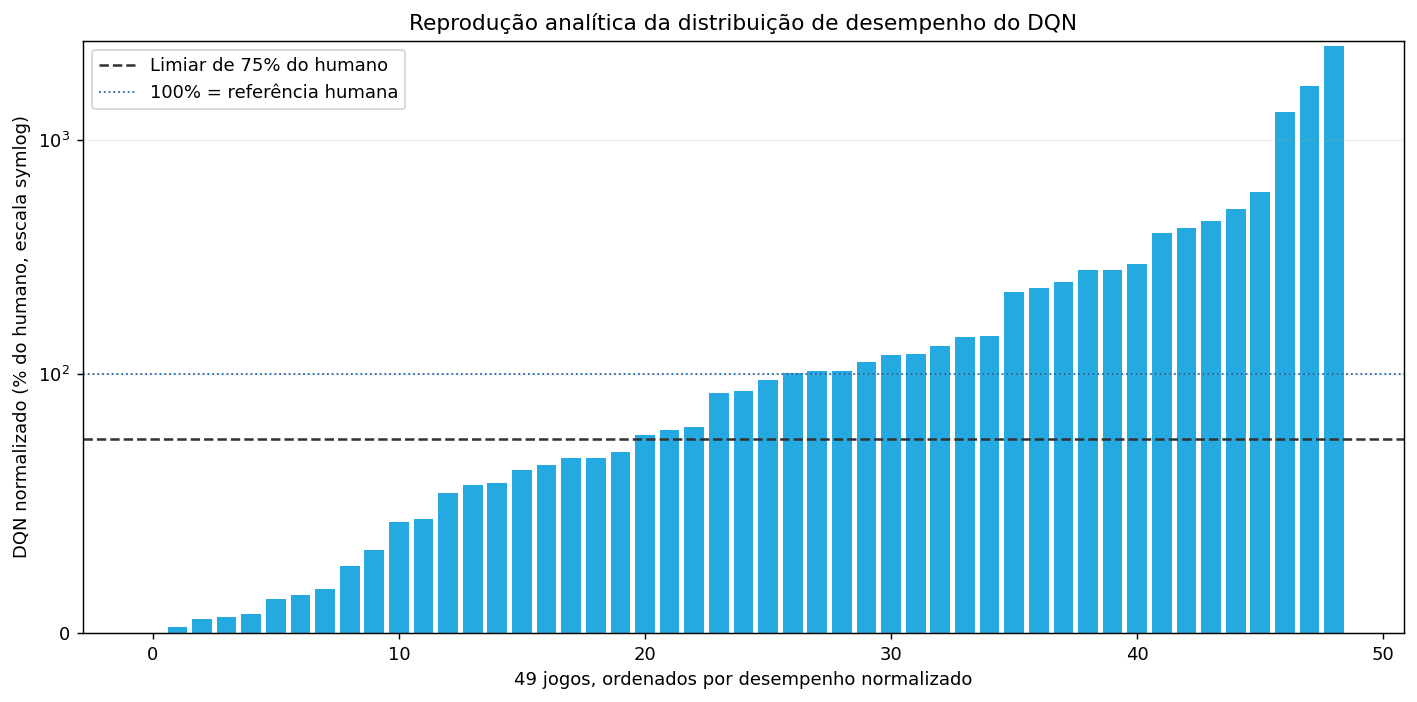

In [5]:
plot_df = df.sort_values("Normalized_DQN_pct").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.bar(range(len(plot_df)), plot_df["Normalized_DQN_pct"], color="#24A9E0")
ax.axhline(75, color="#333333", linewidth=1.4, linestyle="--", label="Limiar de 75% do humano")
ax.axhline(100, color="#1F66B1", linewidth=1.0, linestyle=":", label="100% = referência humana")
ax.set_yscale("symlog", linthresh=100)
ax.set_xlabel("49 jogos, ordenados por desempenho normalizado")
ax.set_ylabel("DQN normalizado (% do humano, escala symlog)")
ax.set_title("Reprodução analítica da distribuição de desempenho do DQN")
ax.legend(loc="upper left")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig("repro_normalized_scores.png", bbox_inches="tight")
plt.show()


## 2. Ablação: experience replay e target network

In [6]:
ablation = pd.DataFrame({
    "Game": ["Breakout", "Enduro", "River Raid", "Seaquest", "Space Invaders"],
    "Replay + Target": [316.8, 1006.3, 7446.6, 2894.4, 1088.9],
    "Replay sem Target": [240.7, 831.4, 4102.8, 822.6, 826.3],
    "Sem Replay + Target": [10.2, 141.9, 2867.7, 1003.0, 373.2],
    "Sem Replay e sem Target": [3.2, 29.1, 1453.0, 275.8, 302.0],
})
ablation


,Game,Replay + Target,Replay sem Target,Sem Replay + Target,Sem Replay e sem Target
0,Breakout,316.8,240.7,10.2,3.2
1,Enduro,1006.3,831.4,141.9,29.1
2,River Raid,7446.6,4102.8,2867.7,1453.0
3,Seaquest,2894.4,822.6,1003.0,275.8
4,Space Invaders,1088.9,826.3,373.2,302.0


In [7]:
configs = ["Replay + Target", "Replay sem Target", "Sem Replay + Target", "Sem Replay e sem Target"]
rel = ablation.copy()
baseline = ablation["Replay + Target"].copy()
for c in configs:
    rel[c] = 100 * ablation[c] / baseline
summary = rel[configs].mean().round(1)
summary


Replay + Target            100.0
Replay sem Target           63.6
Sem Replay + Target         25.0
Sem Replay e sem Target     12.1
dtype: float64

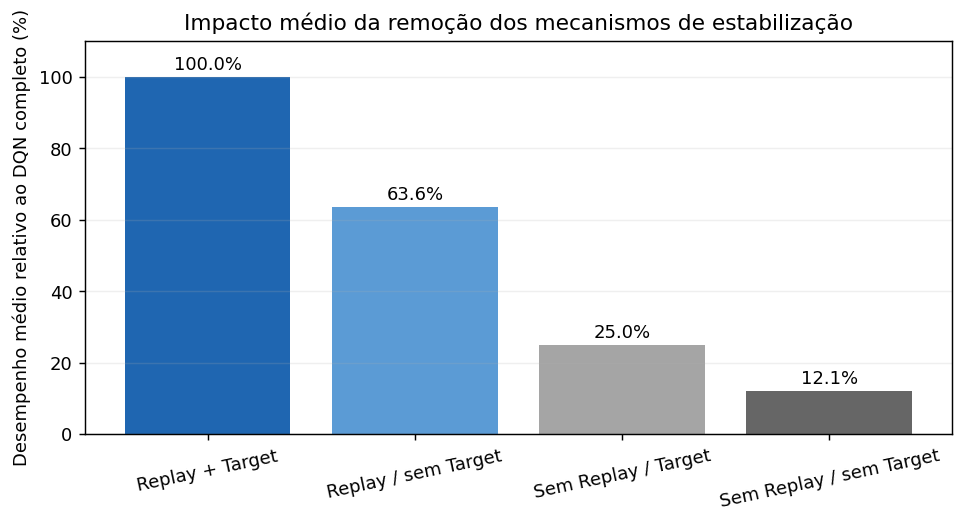

In [8]:
labels = ["Replay + Target", "Replay / sem Target", "Sem Replay / Target", "Sem Replay / sem Target"]
fig, ax = plt.subplots(figsize=(8.6, 4.8))
ax.bar(labels, summary.values, color=["#1F66B1", "#5B9BD5", "#A5A5A5", "#666666"])
ax.set_ylabel("Desempenho médio relativo ao DQN completo (%)")
ax.set_title("Impacto médio da remoção dos mecanismos de estabilização")
ax.set_ylim(0, 110)
ax.grid(axis="y", alpha=0.2)
ax.tick_params(axis="x", labelrotation=12)
for i, v in enumerate(summary.values):
    ax.text(i, v + 2, f"{v:.1f}%", ha="center")
fig.subplots_adjust(bottom=0.23, top=0.86)
fig.savefig("repro_ablation.png", bbox_inches="tight")
plt.show()


### Leitura do resultado

- A combinação **experience replay + target network** é a melhor configuração nos cinco jogos avaliados.
- Remover somente a target network reduz fortemente o desempenho médio.
- Remover replay é ainda mais prejudicial em vários jogos; remover os dois mecanismos é a pior configuração.
- Isso sustenta a interpretação central do artigo: os dois mecanismos são importantes para estabilizar o Q-learning com redes neurais profundas.


## Referência

Mnih, V. et al. **Human-level control through deep reinforcement learning.** *Nature* 518, 529–533 (2015). DOI: 10.1038/nature14236.
